In [1]:
import numpy as np
import os
import scipy.io
import matplotlib.pyplot as plt

from functions_infer_aal90_order_v1 import (
    infer_aal90_order,
    ORDER_LLRR, ORDER_LRLR, ORDER_UNDET, LEGACY_LABELS,
)

## 1. Load SC and check symmetry

Input asymmetry (SC vs SC.T) : 0.00e+00

                               H1 LLRR     H2 LRLR
  log10(intra/inter)            0.8875     -0.1254
  |log10(LL/RR)|                0.0111      0.0103
  Spearman LL~RR                0.1155      0.2060
  TOTAL                         0.9342     -0.0326

Decision margin              : 0.9668  (tol = 0.3)
Inferred ordering            : non-symmetric LLRR
non-symmetric


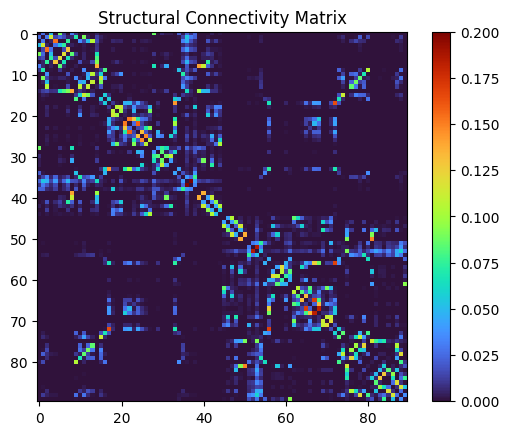

In [2]:
### LOAD SC
## SC directory
SC_dir = './'
data = scipy.io.loadmat(f'{SC_dir}SC_AAL90.mat')
SC = np.array(data['SC']).copy()
NPARCELS = SC.shape[0]
del data

order, order_info = infer_aal90_order(SC)
PARCELS_ORDER = LEGACY_LABELS[order]
if PARCELS_ORDER is None:
    raise RuntimeError(
        f"Parcel ordering undetermined (margin={order_info['margin']:.3f}); "
        "resolve against the atlas label file before proceeding."
    )
print(PARCELS_ORDER)

plt.imshow(SC, cmap='turbo')
plt.title("Structural Connectivity Matrix")
plt.colorbar()
plt.show()

# 2. AAL90 $\to$ Yeo7 mapping

In [3]:
Yeo7_to_AAL90_labels = {
    "Visual": [
        "Calcarine_L", "Calcarine_R",
        "Cuneus_L", "Cuneus_R",
        "Lingual_L", "Lingual_R",
        "Occipital_Sup_L", "Occipital_Sup_R",
        "Occipital_Mid_L", "Occipital_Mid_R",
        "Occipital_Inf_L", "Occipital_Inf_R",
        "Fusiform_L", "Fusiform_R",
    ],
    "Somatomotor": [
        "Precentral_L", "Precentral_R",
        "Rolandic_Oper_L", "Rolandic_Oper_R",
        "Supp_Motor_Area_L", "Supp_Motor_Area_R",
        "Postcentral_L", "Postcentral_R",
        "Paracentral_Lobule_L", "Paracentral_Lobule_R",
        "Heschl_L", "Heschl_R",
    ],
    "Dorsal\n attention": [
        "Parietal_Sup_L", "Parietal_Sup_R",
        "Parietal_Inf_L", "Parietal_Inf_R",
    ],
    "Ventral att./\n Salience": [
        "Insula_L", "Insula_R",
        "Cingulum_Ant_L", "Cingulum_Ant_R",
        "Cingulum_Mid_L", "Cingulum_Mid_R",
        "SupraMarginal_L", "SupraMarginal_R",
        "Temporal_Sup_L", "Temporal_Sup_R",
    ],
    "Limbic": [
        "Frontal_Sup_Orb_L", "Frontal_Sup_Orb_R",
        "Frontal_Mid_Orb_L", "Frontal_Mid_Orb_R",
        "Frontal_Inf_Orb_L", "Frontal_Inf_Orb_R",
        "Olfactory_L", "Olfactory_R",
        "Frontal_Med_Orb_L", "Frontal_Med_Orb_R",
        "Rectus_L", "Rectus_R",
        "Amygdala_L", "Amygdala_R",
        "Temporal_Pole_Sup_L", "Temporal_Pole_Sup_R",
        "Temporal_Pole_Mid_L", "Temporal_Pole_Mid_R",
    ],
    "Frontal\n control": [
        "Frontal_Sup_L", "Frontal_Sup_R",
        "Frontal_Mid_L", "Frontal_Mid_R",
        "Frontal_Inf_Oper_L", "Frontal_Inf_Oper_R",
        "Frontal_Inf_Tri_L", "Frontal_Inf_Tri_R",
    ],
    "Default\n mode": [
        "Frontal_Sup_Medial_L", "Frontal_Sup_Medial_R",
        "Cingulum_Post_L", "Cingulum_Post_R",
        "Hippocampus_L", "Hippocampus_R",
        "ParaHippocampal_L", "ParaHippocampal_R",
        "Angular_L", "Angular_R",
        "Precuneus_L", "Precuneus_R",
        "Temporal_Mid_L", "Temporal_Mid_R",
        "Temporal_Inf_L", "Temporal_Inf_R",
    ],
}

# Yeo7 cortical networks + a subcortical extension (Caudate/Putamen/Pallidum/
# Thalamus have no cortical Yeo7 assignment but are needed for full AAL-90
# coverage). Built from Yeo7_to_AAL90_labels rather than duplicated, so the
# two dicts cannot drift out of sync.
Yeo7subcort_to_AAL90_labels = {
    **Yeo7_to_AAL90_labels,
    "Subcortical\n extension": [
        "Caudate_L", "Caudate_R",
        "Putamen_L", "Putamen_R",
        "Pallidum_L", "Pallidum_R",
        "Thalamus_L", "Thalamus_R",
    ],
}

### Non-symmetric AAL-90 Order (L then R)
AAL_labels_non_symmetric = [
    'Precentral_L', 'Frontal_Sup_L', 'Frontal_Sup_Orb_L', 'Frontal_Mid_L', 'Frontal_Mid_Orb_L',
    'Frontal_Inf_Oper_L', 'Frontal_Inf_Tri_L', 'Frontal_Inf_Orb_L', 'Rolandic_Oper_L', 'Supp_Motor_Area_L',
    'Olfactory_L', 'Frontal_Sup_Medial_L', 'Frontal_Med_Orb_L', 'Rectus_L', 'Insula_L',
    'Cingulum_Ant_L', 'Cingulum_Mid_L', 'Cingulum_Post_L', 'Hippocampus_L', 'ParaHippocampal_L',
    'Amygdala_L', 'Calcarine_L', 'Cuneus_L', 'Lingual_L', 'Occipital_Sup_L',
    'Occipital_Mid_L', 'Occipital_Inf_L', 'Fusiform_L', 'Postcentral_L', 'Parietal_Sup_L',
    'Parietal_Inf_L', 'SupraMarginal_L', 'Angular_L', 'Precuneus_L', 'Paracentral_Lobule_L',
    'Caudate_L', 'Putamen_L', 'Pallidum_L', 'Thalamus_L', 'Heschl_L',
    'Temporal_Sup_L', 'Temporal_Pole_Sup_L', 'Temporal_Mid_L', 'Temporal_Pole_Mid_L', 'Temporal_Inf_L',

    'Precentral_R', 'Frontal_Sup_R', 'Frontal_Sup_Orb_R', 'Frontal_Mid_R', 'Frontal_Mid_Orb_R',
    'Frontal_Inf_Oper_R', 'Frontal_Inf_Tri_R', 'Frontal_Inf_Orb_R', 'Rolandic_Oper_R', 'Supp_Motor_Area_R',
    'Olfactory_R', 'Frontal_Sup_Medial_R', 'Frontal_Med_Orb_R', 'Rectus_R', 'Insula_R',
    'Cingulum_Ant_R', 'Cingulum_Mid_R', 'Cingulum_Post_R', 'Hippocampus_R', 'ParaHippocampal_R',
    'Amygdala_R', 'Calcarine_R', 'Cuneus_R', 'Lingual_R', 'Occipital_Sup_R',
    'Occipital_Mid_R', 'Occipital_Inf_R', 'Fusiform_R', 'Postcentral_R', 'Parietal_Sup_R',
    'Parietal_Inf_R', 'SupraMarginal_R', 'Angular_R', 'Precuneus_R', 'Paracentral_Lobule_R',
    'Caudate_R', 'Putamen_R', 'Pallidum_R', 'Thalamus_R', 'Heschl_R',
    'Temporal_Sup_R', 'Temporal_Pole_Sup_R', 'Temporal_Mid_R', 'Temporal_Pole_Mid_R', 'Temporal_Inf_R'
]

### Symmetric AAL-90 Order (Interleaved L-R)
AAL_labels_symmetric = []
for i in range(45):
    AAL_labels_symmetric.append(AAL_labels_non_symmetric[i])
    AAL_labels_symmetric.append(AAL_labels_non_symmetric[i + 45])

print('Parcels order is:',PARCELS_ORDER)
if PARCELS_ORDER == 'non-symmetric':
    AAL_labels = AAL_labels_non_symmetric.copy()
elif PARCELS_ORDER == 'symmetric':
    AAL_labels = AAL_labels_symmetric.copy()

Parcels order is: non-symmetric


In [4]:
for i, region in enumerate(AAL_labels):
    print(i+1, region)

1 Precentral_L
2 Frontal_Sup_L
3 Frontal_Sup_Orb_L
4 Frontal_Mid_L
5 Frontal_Mid_Orb_L
6 Frontal_Inf_Oper_L
7 Frontal_Inf_Tri_L
8 Frontal_Inf_Orb_L
9 Rolandic_Oper_L
10 Supp_Motor_Area_L
11 Olfactory_L
12 Frontal_Sup_Medial_L
13 Frontal_Med_Orb_L
14 Rectus_L
15 Insula_L
16 Cingulum_Ant_L
17 Cingulum_Mid_L
18 Cingulum_Post_L
19 Hippocampus_L
20 ParaHippocampal_L
21 Amygdala_L
22 Calcarine_L
23 Cuneus_L
24 Lingual_L
25 Occipital_Sup_L
26 Occipital_Mid_L
27 Occipital_Inf_L
28 Fusiform_L
29 Postcentral_L
30 Parietal_Sup_L
31 Parietal_Inf_L
32 SupraMarginal_L
33 Angular_L
34 Precuneus_L
35 Paracentral_Lobule_L
36 Caudate_L
37 Putamen_L
38 Pallidum_L
39 Thalamus_L
40 Heschl_L
41 Temporal_Sup_L
42 Temporal_Pole_Sup_L
43 Temporal_Mid_L
44 Temporal_Pole_Mid_L
45 Temporal_Inf_L
46 Precentral_R
47 Frontal_Sup_R
48 Frontal_Sup_Orb_R
49 Frontal_Mid_R
50 Frontal_Mid_Orb_R
51 Frontal_Inf_Oper_R
52 Frontal_Inf_Tri_R
53 Frontal_Inf_Orb_R
54 Rolandic_Oper_R
55 Supp_Motor_Area_R
56 Olfactory_R
57 Frontal

In [5]:
# Yeo7 network -> index mapping (cortex only)
RSN_indexes = {}
for rsn, regions in Yeo7_to_AAL90_labels.items():
    indexes = [i for i, region in enumerate(AAL_labels) if region in regions]
    RSN_indexes[rsn] = indexes

# Yeo7 + subcortical extension -> index mapping (full 90-parcel coverage)
RSN_indexes_extended = {}
for rsn, regions in Yeo7subcort_to_AAL90_labels.items():
    indexes = [i for i, region in enumerate(AAL_labels) if region in regions]
    RSN_indexes_extended[rsn] = indexes

## 3. Test bar plot

In [6]:
import itertools
np.random.seed(0)

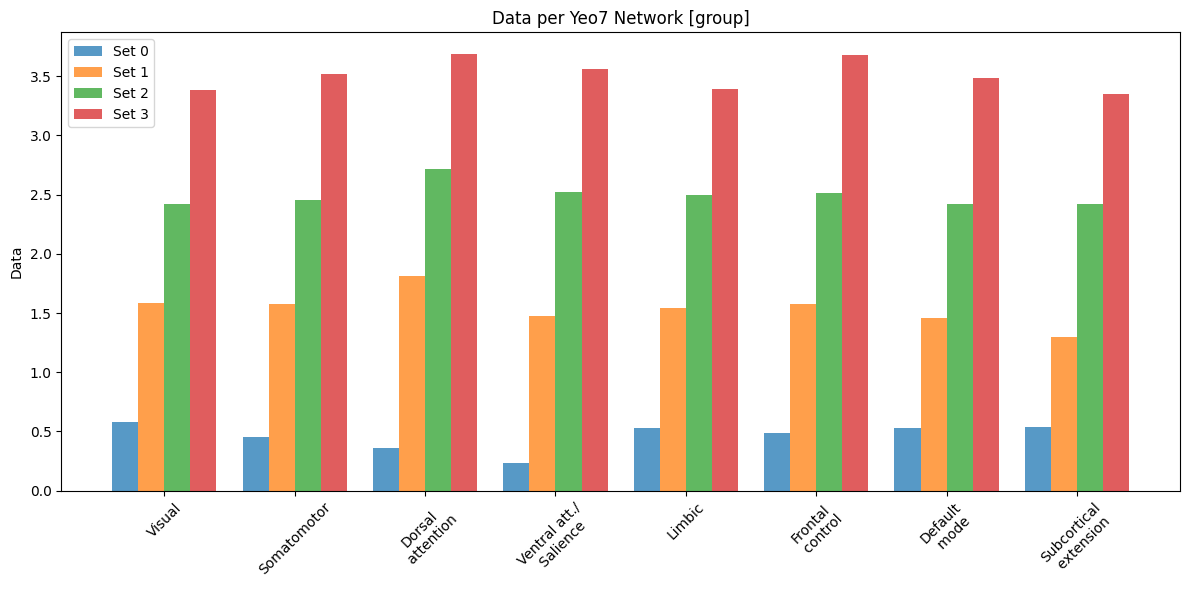

In [7]:
# Your non-equilibrium vector: 90 elements
data_set0 = np.random.rand(NPARCELS) + 0
data_set1 = np.random.rand(NPARCELS) + 1
data_set2 = np.random.rand(NPARCELS) + 2
data_set3 = np.random.rand(NPARCELS) + 3

label_set0 = 'Set 0'
label_set1 = 'Set 1'
label_set2 = 'Set 2'
label_set3 = 'Set 3'

# Compute mean non-equilibrium per Yeo7 network (+ subcortical extension)
RSN_data_set0 = {rsn: np.mean(data_set0[indexes]) for rsn, indexes in RSN_indexes_extended.items()}
RSN_data_set1 = {rsn: np.mean(data_set1[indexes]) for rsn, indexes in RSN_indexes_extended.items()}
RSN_data_set2 = {rsn: np.mean(data_set2[indexes]) for rsn, indexes in RSN_indexes_extended.items()}
RSN_data_set3 = {rsn: np.mean(data_set3[indexes]) for rsn, indexes in RSN_indexes_extended.items()}

# Prepare data
RSNs = list(RSN_data_set0.keys())
x = np.arange(len(RSNs))  # the label locations
width = 0.2  # width of the bars

# Values
values0 = [RSN_data_set0[rsn] for rsn in RSNs]
values1 = [RSN_data_set1[rsn] for rsn in RSNs]
values2 = [RSN_data_set2[rsn] for rsn in RSNs]
values3 = [RSN_data_set3[rsn] for rsn in RSNs]

# Plot
plt.figure(figsize=(12, 6))
plt.bar(x - 3*width/2, values0, width, alpha=0.75, label=f'{label_set0}')
plt.bar(x -   width/2, values1, width, alpha=0.75, label=f'{label_set1}')
plt.bar(x +   width/2, values2, width, alpha=0.75, label=f'{label_set2}')
plt.bar(x + 3*width/2, values3, width, alpha=0.75, label=f'{label_set3}')

# Labels and legend
plt.ylabel("Data")
plt.title("Data per Yeo7 Network [group]")
plt.xticks(x, RSNs, rotation=45)
plt.tight_layout()
plt.legend()
plt.show()